In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor

from statsmodels.tsa.statespace.sarimax import SARIMAX

In [18]:
data = pd.read_csv(r'C:\Users\asus\Desktop\MachineLearning_project\Dogecoin Price Prediction with Machine Learning\DOGE-USD.csv')

In [19]:
data.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2017-11-09,0.001207,0.001415,0.001181,0.001415,0.001415,6259550.0
1,2017-11-10,0.001421,0.001431,0.001125,0.001163,0.001163,4246520.0
2,2017-11-11,0.001146,0.001257,0.001141,0.001201,0.001201,2231080.0
3,2017-11-12,0.001189,0.001210,0.001002,0.001038,0.001038,3288960.0
4,2017-11-13,0.001046,0.001212,0.001019,0.001211,0.001211,2481270.0


In [20]:
data.corr(numeric_only=True)

,Open,High,Low,Close,Adj Close,Volume
Open,1.000000,0.993904,0.993707,0.992514,0.992514,0.554850
High,0.993904,1.000000,0.986497,0.995104,0.995104,0.619321
Low,0.993707,0.986497,1.000000,0.994575,0.994575,0.519991
Close,0.992514,0.995104,0.994575,1.000000,1.000000,0.588678
Adj Close,0.992514,0.995104,0.994575,1.000000,1.000000,0.588678
Volume,0.554850,0.619321,0.519991,0.588678,0.588678,1.000000


In [21]:

data['Date']=pd.to_datetime(data['Date'],infer_datetime_format=True)
data

C:\Users\asus\AppData\Local\Temp\ipykernel_25052\955471102.py:1: UserWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  data['Date']=pd.to_datetime(data['Date'],infer_datetime_format=True)


,Date,Open,High,Low,Close,Adj Close,Volume
0,2017-11-09,0.001207,0.001415,0.001181,0.001415,0.001415,6259550.0
1,2017-11-10,0.001421,0.001431,0.001125,0.001163,0.001163,4246520.0
2,2017-11-11,0.001146,0.001257,0.001141,0.001201,0.001201,2231080.0
3,2017-11-12,0.001189,0.001210,0.001002,0.001038,0.001038,3288960.0
4,2017-11-13,0.001046,0.001212,0.001019,0.001211,0.001211,2481270.0
...,...,...,...,...,...,...,...
1756,2022-08-31,0.061534,0.063333,0.061058,0.061330,0.061330,309748693.0
1757,2022-09-01,0.061336,0.062479,0.060194,0.062372,0.062372,328765413.0
1758,2022-09-02,0.062372,0.062712,0.060947,0.061635,0.061635,273453013.0
1759,2022-09-03,NaN,NaN,NaN,NaN,NaN,NaN


In [22]:
data.set_index('Date',inplace=True)
data.isnull().any()

Open         True
High         True
Low          True
Close        True
Adj Close    True
Volume       True
dtype: bool

In [23]:
data.isnull().sum()

Open         1
High         1
Low          1
Close        1
Adj Close    1
Volume       1
dtype: int64

In [24]:
data = data.dropna()

In [25]:
data.describe()

,Open,High,Low,Close,Adj Close,Volume
count,1760.000000,1760.000000,1760.000000,1760.000000,1760.000000,1.760000e+03
mean,0.059575,0.063096,0.056126,0.059619,0.059619,1.016258e+09
std,0.101325,0.109152,0.093695,0.101379,0.101379,3.563999e+09
min,0.001046,0.001210,0.001002,0.001038,0.001038,1.431720e+06
25%,0.002550,0.002616,0.002500,0.002548,0.002548,2.307671e+07
50%,0.003476,0.003603,0.003356,0.003495,0.003495,8.981855e+07
75%,0.070633,0.075035,0.068478,0.070657,0.070657,6.565853e+08
max,0.687801,0.737567,0.608168,0.684777,0.684777,6.941068e+10


Text(0.5, 1.0, 'Date  vs Close of 2021')

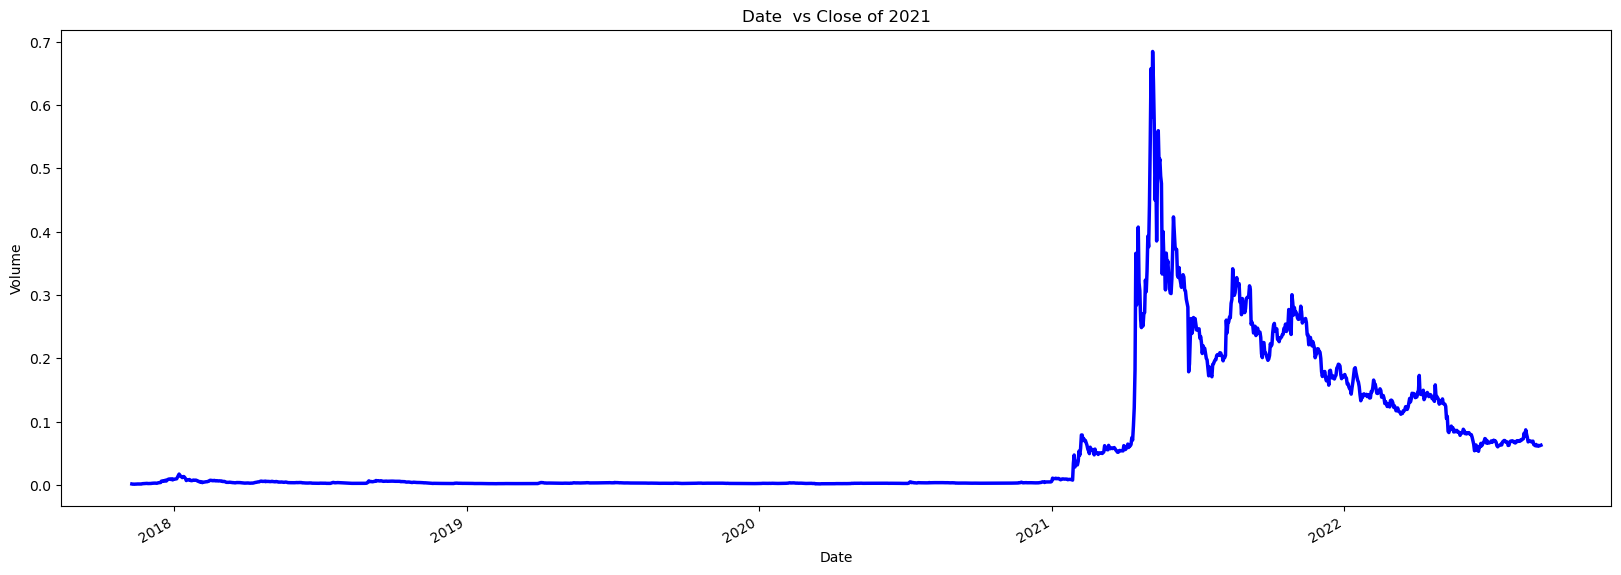

In [26]:
plt.figure(figsize=(20,7))
x= data.groupby('Date')['Close'].mean()
x.plot(linewidth=2.5,color='b')
plt.xlabel('Date')
plt.ylabel('Volume')
plt.title('Date  vs Close of 2021')

In [31]:
#The column 'Close' is our predicted feature
data["gap"] = (data["High"] - data["Low"]) * data["Volume"]
data["y"] = data["High"] / data["Volume"]
data["z"] = data["Low"] / data["Volume"]
data["a"] = data["High"] / data["Low"]
data["b"] = (data["High"] / data["Low"]) * data["Volume"]
abs(data.corr()["Close"].sort_values(ascending=False))


C:\Users\asus\AppData\Local\Temp\ipykernel_25052\543315695.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["gap"] = (data["High"] - data["Low"]) * data["Volume"]
C:\Users\asus\AppData\Local\Temp\ipykernel_25052\543315695.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["y"] = data["High"] / data["Volume"]
C:\Users\asus\AppData\Local\Temp\ipykernel_25052\543315695.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_

Close        1.000000
Adj Close    1.000000
High         0.995104
Low          0.994575
Open         0.992514
Volume       0.588678
b            0.456479
gap          0.383333
a            0.172057
z            0.063251
y            0.063868
Name: Close, dtype: float64

In [32]:
data =data[["Close","Volume","gap","a","b"]]
data

,Close,Volume,gap,a,b
Date,,,,,
2017-11-09,0.001415,6259550.0,1.464735e+03,1.198137,7.499800e+06
2017-11-10,0.001163,4246520.0,1.299435e+03,1.272000,5.401573e+06
2017-11-11,0.001201,2231080.0,2.588053e+02,1.101665,2.457903e+06
2017-11-12,0.001038,3288960.0,6.841037e+02,1.207585,3.971698e+06
2017-11-13,0.001211,2481270.0,4.788851e+02,1.189401,2.951226e+06
...,...,...,...,...,...
2022-08-30,0.061525,328934727.0,1.269030e+06,1.063716,3.498931e+08
2022-08-31,0.061330,309748693.0,7.046783e+05,1.037260,3.212898e+08
2022-09-01,0.062372,328765413.0,7.512290e+05,1.037961,3.412455e+08


In [35]:
#ARIMA model for Time Series Analysis
df2 = data.tail(30)
df2



,Close,Volume,gap,a,b
Date,,,,,
2022-08-05,0.069765,3.362167e+08,9.619161e+05,1.042539,3.505190e+08
2022-08-06,0.068674,2.779791e+08,6.707636e+05,1.035182,2.877590e+08
2022-08-07,0.068940,2.048625e+08,4.408641e+05,1.031765,2.113700e+08
2022-08-08,0.070055,3.991834e+08,1.251440e+06,1.045486,4.173405e+08
2022-08-09,0.069125,6.113271e+08,3.315838e+06,1.079226,6.597604e+08
2022-08-10,0.071195,4.311727e+08,1.690197e+06,1.058170,4.562539e+08
2022-08-11,0.070930,5.639086e+08,2.209958e+06,1.055410,5.951549e+08
2022-08-12,0.072345,3.204104e+08,7.859666e+05,1.035029,3.316341e+08
2022-08-13,0.072840,4.462874e+08,1.298250e+06,1.040430,4.643310e+08


In [36]:
train=df2[:11]
test =df2[-19:]
print(train.shape,test.shape)

(11, 5) (19, 5)


In [40]:
#Model Development SARIMAX
model = SARIMAX(endog=train["Close"],exog=train.drop("Close",axis=1),order=(2,1,1))
results = model.fit()
print(results.summary())


C:\Users\asus\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\asus\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\asus\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params


                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                   11
Model:               SARIMAX(2, 1, 1)   Log Likelihood                  47.663
Date:                Tue, 10 Nov 2026   AIC                            -79.326
Time:                        11:49:28   BIC                            -76.905
Sample:                    08-05-2022   HQIC                           -81.981
                         - 08-15-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Volume      7.491e-10   1.84e-10      4.077      0.000    3.89e-10    1.11e-09
gap          1.13e-08   2.45e-09      4.615      0.000     6.5e-09    1.61e-08
a             -0.0073   5.05e-15  -1.44e+12      0.0

C:\Users\asus\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [42]:
start =11 
end =29
predictions = results.predict(start=start,end =end,exog=test.drop("Close",axis =1))

In [43]:
predictions

2022-08-16    0.097293
2022-08-17    0.083717
2022-08-18    0.075957
2022-08-19    0.069575
2022-08-20    0.071583
2022-08-21    0.072099
2022-08-22    0.071244
2022-08-23    0.072458
2022-08-24    0.072406
2022-08-25    0.071893
2022-08-26    0.068140
2022-08-27    0.071804
2022-08-28    0.071866
2022-08-29    0.071522
2022-08-30    0.070720
2022-08-31    0.071736
2022-09-01    0.071452
2022-09-02    0.072203
2022-09-03    0.072785
Freq: D, Name: predicted_mean, dtype: float64

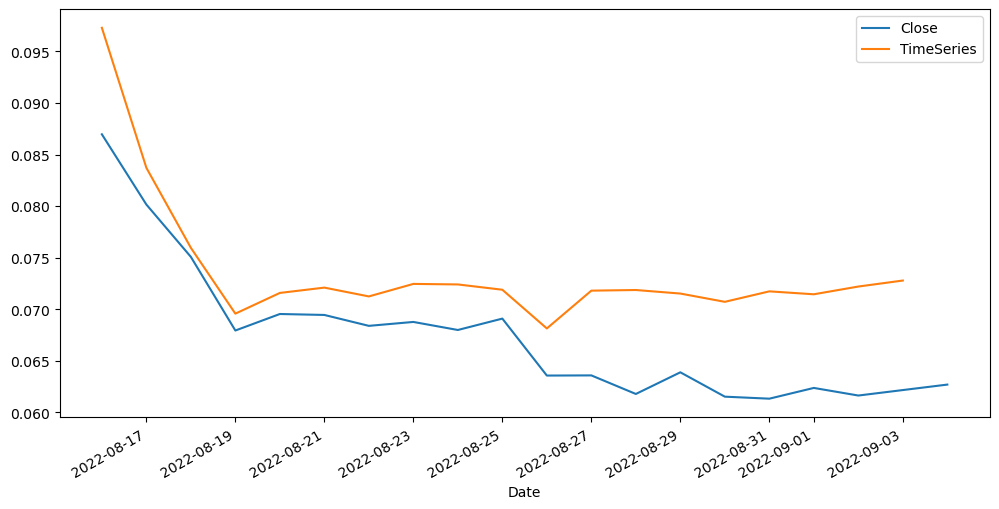

In [45]:
test['Close'].plot(legend=True, figsize =(12,6))
predictions.plot(label='TimeSeries',legend=True);